# 03 · 探索性数据分析（EDA）

本阶段从客户画像、营销触达和历史结果中识别与定期存款订购率相关的模式。

## 分析边界

订购率用于比较不同群体。`duration` 会单独描述，但不能用于通话前客户筛选模型。

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.visualization import save_subscription_rate_chart, subscription_rate_by_category

DATA_PATH = PROJECT_ROOT / 'data/processed/bank_marketing_clean.csv'
FIGURE_DIR = PROJECT_ROOT / 'figures/exploratory'
SUMMARY_PATH = PROJECT_ROOT / 'data/processed/eda_subscription_rates.csv'
sns.set_theme(style='whitegrid', palette='deep')
df = pd.read_csv(DATA_PATH)
print(f'分析数据：{df.shape[0]:,} 行 × {df.shape[1]} 列')

分析数据：41,176 行 × 22 列


## 客户、触达和历史营销结果

以下变量兼具业务解释性和通话前可获得性。

In [2]:
analysis_categories = ['job', 'education', 'contact', 'month', 'poutcome']
rate_tables = []

for category in analysis_categories:
    summary = subscription_rate_by_category(df, category)
    summary.insert(0, 'variable', category)
    rate_tables.append(summary)
    save_subscription_rate_chart(
        summary.drop(columns='variable'), category, FIGURE_DIR / f'subscription_rate_by_{category}.png'
    )

all_rates = pd.concat(rate_tables, ignore_index=True)
all_rates.to_csv(SUMMARY_PATH, index=False)
display(all_rates.sort_values(['variable', 'subscription_rate'], ascending=[True, False]))

,variable,job,customer_count,subscription_rate,education,contact,month,poutcome
20,contact,NaN,26135,0.147389,NaN,cellular,NaN,NaN
21,contact,NaN,15041,0.052324,NaN,telephone,NaN,NaN
12,education,NaN,18,0.222222,illiterate,NaN,NaN,NaN
13,education,NaN,1730,0.145087,unknown,NaN,NaN,NaN
14,education,NaN,12164,0.137208,university.degree,NaN,NaN,NaN
15,education,NaN,5240,0.113550,professional.course,NaN,NaN,NaN
16,education,NaN,9512,0.108389,high.school,NaN,NaN,NaN
17,education,NaN,4176,0.102490,basic.4y,NaN,NaN,NaN
18,education,NaN,2291,0.082060,basic.6y,NaN,NaN,NaN
19,education,NaN,6045,0.078246,basic.9y,NaN,NaN,NaN


## 年龄和活动频率

将年龄分箱后比较订购率；同时检查单次活动中联系次数（`campaign`）的差异。

In [3]:
eda_df = df.copy()
eda_df['age_group'] = pd.cut(eda_df['age'], bins=[0, 25, 35, 45, 55, 65, 120], right=False)
age_summary = subscription_rate_by_category(eda_df, 'age_group')
age_summary['age_group'] = age_summary['age_group'].astype(str)
save_subscription_rate_chart(age_summary, 'age_group', FIGURE_DIR / 'subscription_rate_by_age_group.png')
display(age_summary)

campaign_summary = df.groupby('target_subscription')['campaign'].agg(['count', 'mean', 'median']).rename(index={0: 'no', 1: 'yes'})
display(campaign_summary)

,age_group,customer_count,subscription_rate
0,"[65, 120)",662,0.472810
1,"[0, 25)",1067,0.239925
2,"[55, 65)",3566,0.135726
3,"[25, 35)",13684,0.121748
4,"[35, 45)",13495,0.086551
5,"[45, 55)",8702,0.086417


,count,mean,median
target_subscription,,,
no,36537,2.633385,2.0
yes,4639,2.051951,2.0


## 数值变量与订购结果

相关性只用于发现线索，不代表因果关系。

target_subscription,no_median,yes_median
age,38.000,37.000
duration,164.000,449.000
campaign,2.000,2.000
pdays,999.000,999.000
previous,0.000,0.000
emp.var.rate,1.100,-1.800
cons.price.idx,93.918,93.200
cons.conf.idx,-41.800,-40.400
euribor3m,4.857,1.266
nr.employed,5195.800,5099.100


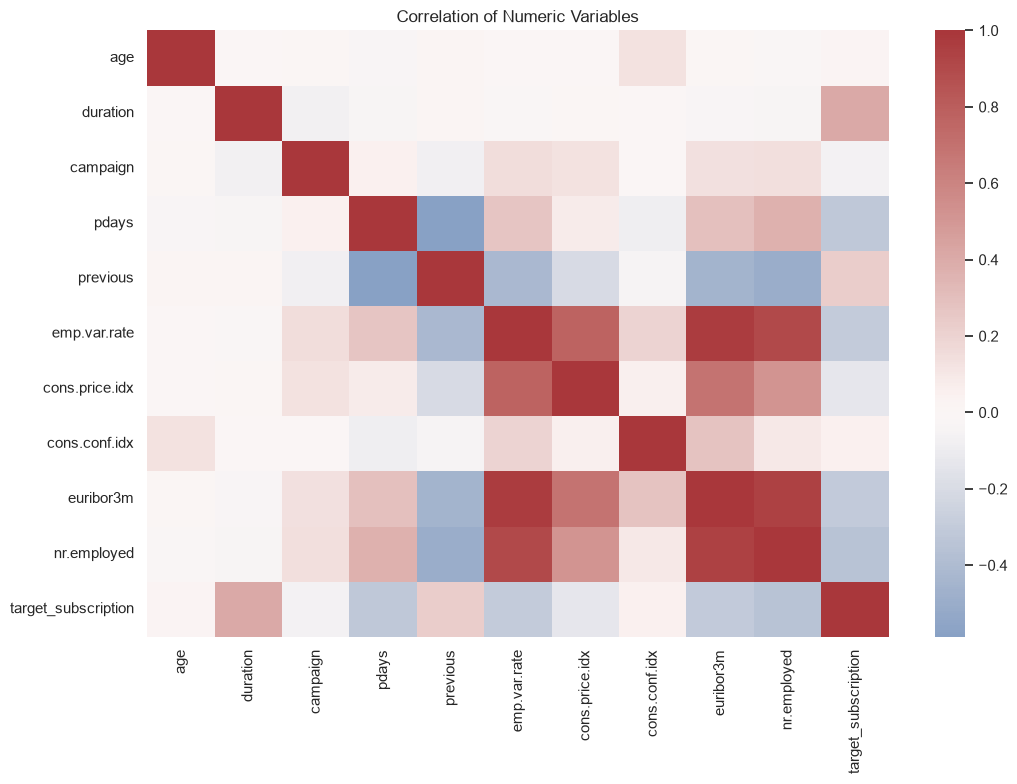

In [4]:
numeric_columns = df.select_dtypes(include='number').columns.tolist()
numeric_summary = df.groupby('target_subscription')[numeric_columns].median().T.rename(columns={0: 'no_median', 1: 'yes_median'})
display(numeric_summary)

correlation_columns = [column for column in numeric_columns if column != 'target_subscription'] + ['target_subscription']
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(df[correlation_columns].corr(), cmap='vlag', center=0, ax=ax)
ax.set_title('Correlation of Numeric Variables')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'numeric_correlation_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()

## 下一步

基于这些模式进行特征工程和训练/测试集划分；通话前预测模型排除 `duration`。